
# Carbon Footprint Calculator Mini-Project
**Submitted by:** Anubhav Shukla
**Program:** B.Tech 1st Year (CSE - AI/ML)  

**Admission No.-**: 2026B15310137


**Topics Used:** Python, NumPy, Pandas, Matplotlib

### Step 1: Import Required Libraries
We import `numpy` for numerical arrays and vectorized calculations, `pandas` for tabular data organization, and `matplotlib` for plotting charts.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print('Libraries imported successfully!')

Libraries imported successfully!


### Step 2: Define Standard Carbon Emission Factors
Each activity has an emission factor measured in **kg $CO_2$ per unit**.

In [ ]:
categories = ['Electricity (kWh)', 'Car Travel (km)', 'Public Transit (km)', 'LPG Gas (kg)', 'Non-Veg Meals', 'Veg Meals']
emission_factors = np.array([0.82, 0.192, 0.045, 2.98, 2.50, 0.70])

factors_df = pd.DataFrame({
    'Activity Category': categories,
    'Emission Factor (kg CO2/unit)': emission_factors
})
display(factors_df)

,Activity Category,Emission Factor (kg CO2/unit)
0,Electricity (kWh),0.820
1,Car Travel (km),0.192
2,Public Transit (km),0.045
3,LPG Gas (kg),2.980
4,Non-Veg Meals,2.500
5,Veg Meals,0.700


### Step 3: Multi-User Monthly Footprint Analysis (NumPy + Pandas)
Using NumPy's element-wise multiplication (`sample_usage * emission_factors`), we calculate emissions for 5 sample profiles simultaneously.

In [ ]:
sample_usage = np.array([
    [180, 120, 300, 14.2, 10, 80],   # User 1 (Hostel Student)
    [320, 450, 50,  14.2, 25, 65],   # User 2 (Small Family)
    [120, 0,   400, 7.0,  0,  90],   # User 3 (Eco-friendly Student)
    [500, 800, 20,  28.4, 40, 50],   # User 4 (High Usage Household)
    [250, 200, 150, 14.2, 15, 75]    # User 5 (Moderate User)
])

user_names = ['User 1 (Hostel)', 'User 2 (Family)', 'User 3 (Eco)', 'User 4 (High)', 'User 5 (Moderate)']

# Vectorized calculation using NumPy
emissions_matrix = sample_usage * emission_factors

# Tabulate results using Pandas DataFrame
df_emissions = pd.DataFrame(emissions_matrix, columns=categories, index=user_names)
df_emissions['Total Monthly CO2 (kg)'] = np.sum(emissions_matrix, axis=1)
df_emissions['Annual Estimate (Tons)'] = np.round((df_emissions['Total Monthly CO2 (kg)'] * 12) / 1000, 2)

print('--- Monthly Carbon Footprint Report (in kg CO2) ---')
display(df_emissions.round(2))

--- Monthly Carbon Footprint Report (in kg CO2) ---


,Electricity (kWh),Car Travel (km),Public Transit (km),LPG Gas (kg),Non-Veg Meals,Veg Meals,Total Monthly CO2 (kg),Annual Estimate (Tons)
User 1 (Hostel),147.6,23.04,13.50,42.32,25.0,56.0,307.46,3.69
User 2 (Family),262.4,86.40,2.25,42.32,62.5,45.5,501.37,6.02
User 3 (Eco),98.4,0.00,18.00,20.86,0.0,63.0,200.26,2.40
User 4 (High),410.0,153.60,0.90,84.63,100.0,35.0,784.13,9.41
User 5 (Moderate),205.0,38.40,6.75,42.32,37.5,52.5,382.47,4.59


### Step 4: Statistical Summary with NumPy

In [ ]:
total_co2 = df_emissions['Total Monthly CO2 (kg)'].to_numpy()

print(f'Average Monthly Footprint : {np.mean(total_co2):.2f} kg CO2')
print(f'Maximum Monthly Footprint : {np.max(total_co2):.2f} kg CO2')
print(f'Minimum Monthly Footprint : {np.min(total_co2):.2f} kg CO2')
print(f'Standard Deviation        : {np.std(total_co2):.2f} kg CO2')

Average Monthly Footprint : 435.14 kg CO2
Maximum Monthly Footprint : 784.13 kg CO2
Minimum Monthly Footprint : 200.26 kg CO2
Standard Deviation        : 200.21 kg CO2


### Step 5: Interactive Personal Carbon Footprint Calculator
Run the cell below to enter your own monthly values and visualize your personal carbon footprint.

Enter your monthly usage values (enter 0 if not applicable):
1. Electricity consumed (kWh): 0.18
2. Petrol Car/Bike distance (km): 1.2
3. Public Bus/Metro distance (km): 0.1
4. LPG Cooking Gas used (kg, 1 cylinder = 14.2 kg): 2
5. Number of Non-Veg meals per month: 1.9
6. Number of Veg meals per month: 0.5

================ YOUR CARBON FOOTPRINT SUMMARY ================


,Category,Usage,CO2 Emitted (kg),Share (%)
0,Electricity (kWh),0.18,0.15,1.3
1,Car Travel (km),1.20,0.23,2.0
2,Public Transit (km),0.10,0.00,0.0
3,LPG Gas (kg),2.00,5.96,52.1
4,Non-Veg Meals,1.90,4.75,41.5
5,Veg Meals,0.50,0.35,3.1


Total Monthly Emission : 11.44 kg CO2
Estimated Annual Total : 0.14 Metric Tons CO2/year
Rating: EXCELLENT! Below the Indian per-capita average (~2.0 tons/year).


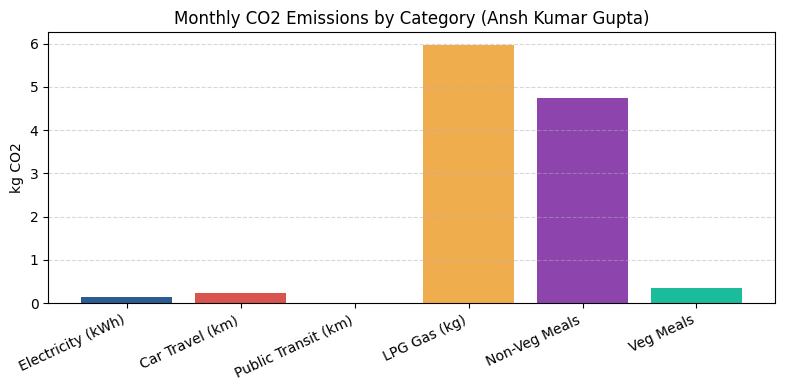

In [ ]:
def calculate_personal_footprint():
    print('Enter your monthly usage values (enter 0 if not applicable):')
    try:
        elec = float(input('1. Electricity consumed (kWh): '))
        car = float(input('2. Petrol Car/Bike distance (km): '))
        bus = float(input('3. Public Bus/Metro distance (km): '))
        lpg = float(input('4. LPG Cooking Gas used (kg, 1 cylinder = 14.2 kg): '))
        non_veg = float(input('5. Number of Non-Veg meals per month: '))
        veg = float(input('6. Number of Veg meals per month: '))
    except ValueError:
        print('Invalid input! Using sample values instead.')
        elec, car, bus, lpg, non_veg, veg = 200, 150, 200, 14.2, 12, 78

    user_input = np.array([elec, car, bus, lpg, non_veg, veg])
    user_emissions = user_input * emission_factors
    total_monthly = np.sum(user_emissions)
    annual_tons = (total_monthly * 12) / 1000

    result_df = pd.DataFrame({
        'Category': categories,
        'Usage': user_input,
        'CO2 Emitted (kg)': np.round(user_emissions, 2),
        'Share (%)': np.round((user_emissions / total_monthly) * 100, 1) if total_monthly > 0 else 0
    })

    print('\n================ YOUR CARBON FOOTPRINT SUMMARY ================')
    display(result_df)
    print(f'Total Monthly Emission : {total_monthly:.2f} kg CO2')
    print(f'Estimated Annual Total : {annual_tons:.2f} Metric Tons CO2/year')

    if annual_tons < 2.0:
        print('Rating: EXCELLENT! Below the Indian per-capita average (~2.0 tons/year).')
    elif annual_tons <= 4.5:
        print('Rating: MODERATE. Consider saving electricity and using public transport more often.')
    else:
        print('Rating: HIGH. Try reducing private vehicle travel and switching to efficient appliances.')

    plt.figure(figsize=(8, 4))
    plt.bar(categories, user_emissions, color=['#2b5c8f', '#d9534f', '#5cb85c', '#f0ad4e', '#8e44ad', '#1abc9c'])
    plt.title('Monthly CO2 Emissions by Category (Ansh Kumar Gupta)')
    plt.ylabel('kg CO2')
    plt.xticks(rotation=25, ha='right')
    plt.grid(axis='y', linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.show()

# Call the function to test interactively in Google Colab:
calculate_personal_footprint()